In [1]:
import pandas as pd
from pathlib import Path
import sys

filnamn = "health_study_dataset.csv"
arbetsmapp = Path.cwd().resolve()

möjliga_filer = [
    mapp / "data" / filnamn
    for mapp in [arbetsmapp, *arbetsmapp.parents]
]

csv_fil = next(
    (fil for fil in möjliga_filer if fil.exists()),
    None
)

if csv_fil is None:
    raise FileNotFoundError(
        f"Hittade inte data/{filnamn}. Kontrollera filnamnet och mappstrukturen"
    )

projektrot = csv_fil.parent.parent
sys.path.insert(0, str(projektrot))

df = pd.read_csv(csv_fil)
bilder_mapp = projektrot/ "bilder"
bilder_mapp.mkdir(parents=True, exist_ok=True)

print(f"CSV-filen lästes in: {csv_fil}")
print(f"Antal rader och kolumner: {df.shape}")



CSV-filen lästes in: C:\Users\PC\Desktop\Hälsostudie Del 1\data\health_study_dataset.csv
Antal rader och kolumner: (800, 9)


In [2]:
df = pd.read_csv(csv_fil)

In [3]:
from src.health_analyzer import HealthAnalyzer

analys = HealthAnalyzer(df, Path("../bilder"))

In [4]:
analys.descriptive_statistics()


,Medelvärde,Median,Min,Max
Ålder (år),49.43,50.00,18.0,90.00
Vikt (kg),73.41,73.20,33.7,114.40
Längd (cm),171.85,171.35,144.4,200.40
Systoliskt blodtryck (mmHg),149.18,149.40,106.8,185.90
Kolesterol (mmol/L),4.93,4.97,2.5,7.88


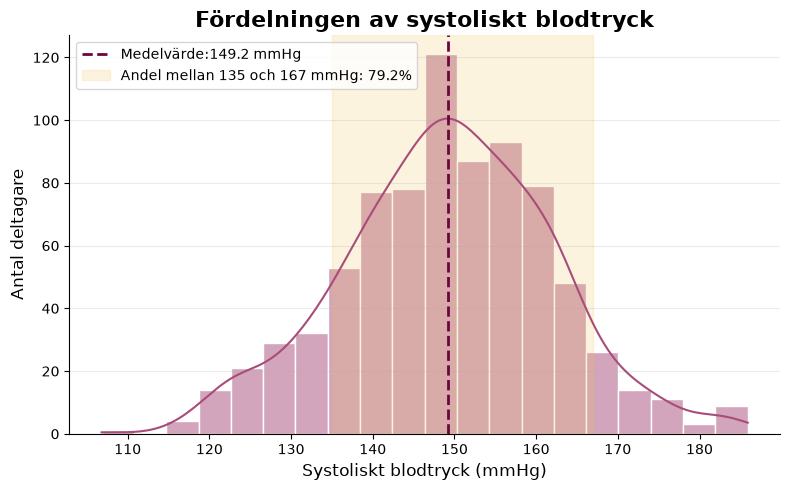

In [5]:
analys.plot_blood_pressure()

Lutning: 0.54 mmHg per år


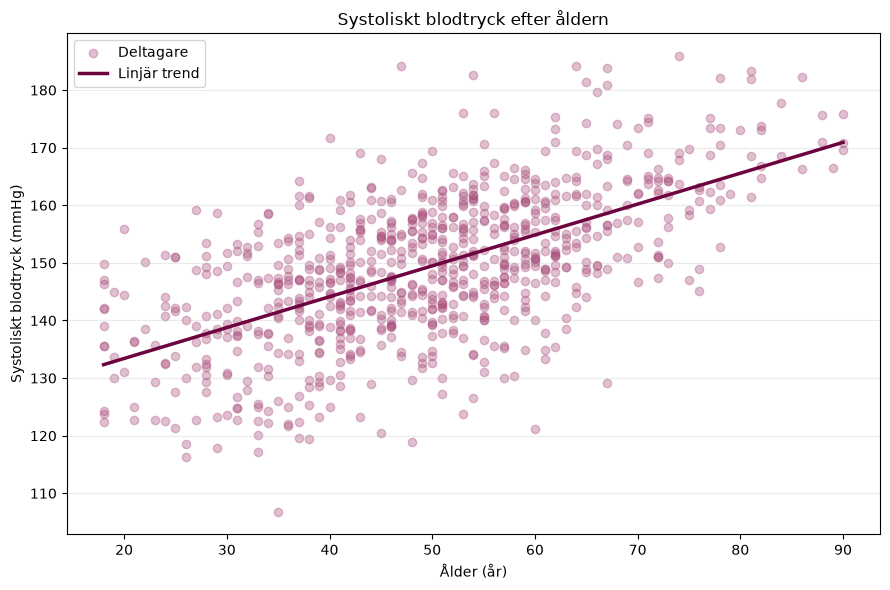

In [6]:
resultat = analys.regression_bp_age()
print(f"Lutning: {resultat['lutning_mmHg_per_år']:.2f} mmHg per år")